# 03 - Exploratory Data Analysis

Looking for patterns that actually explain *why* orders run late, before
throwing any ML at the problem. Every chart here is meant to answer a
specific question, not just decorate the notebook.

In [1]:
import sys, os
sys.path.append("../src")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
CHART_DIR = "../dashboard/charts"
os.makedirs(CHART_DIR, exist_ok=True)

df = pd.read_csv("../data/processed/ontime_joined_raw.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
])
print(df.shape)

(96470, 44)


## 1. How late are the "late" orders, really?

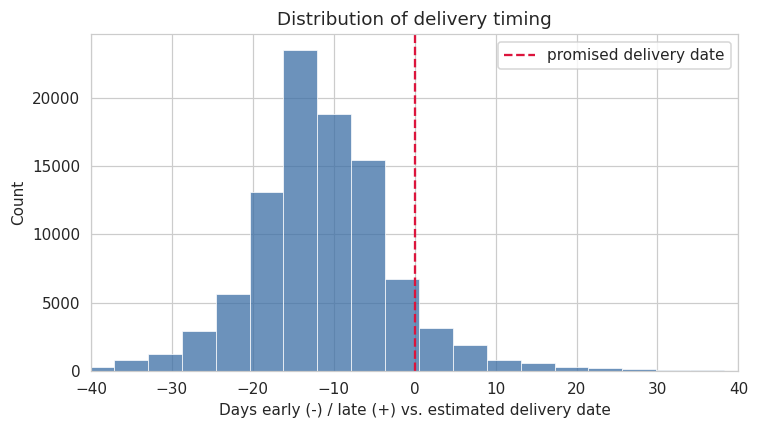

Median delivery: -11.9 days vs. estimate
Share delivered late: 8.1%


In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["delay_days"], bins=80, ax=ax, color="#3b6ea5")
ax.axvline(0, color="crimson", linestyle="--", label="promised delivery date")
ax.set_xlim(-40, 40)
ax.set_xlabel("Days early (-) / late (+) vs. estimated delivery date")
ax.set_title("Distribution of delivery timing")
ax.legend()
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/01_delay_distribution.png")
plt.show()

print(f"Median delivery: {df['delay_days'].median():.1f} days vs. estimate")
print(f"Share delivered late: {(df['delay_days']>0).mean():.1%}")

Most orders actually arrive comfortably *before* the promised date -
Olist / its sellers seem to pad the estimate. The problem isn't that
deliveries are slow on average, it's that a meaningful minority blow
past the promise altogether, some by three, four, even six weeks.

## 2. Has the delay rate been stable over time?

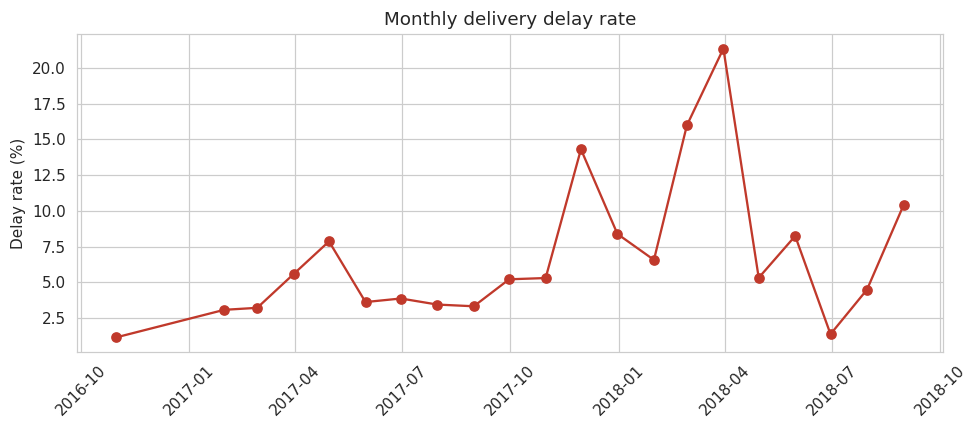

In [3]:
monthly = df.set_index("order_purchase_timestamp").resample("ME")["is_delayed"].agg(["mean", "count"])
monthly = monthly[monthly["count"] > 50]

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(monthly.index, monthly["mean"] * 100, marker="o", color="#c0392b")
ax1.set_ylabel("Delay rate (%)")
ax1.set_title("Monthly delivery delay rate")
for label in ax1.get_xticklabels():
    label.set_rotation(45)
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/02_monthly_delay_trend.png")
plt.show()

Delay rate is far from flat: it climbs sharply around **November 2017**
(Black Friday order surge outrunning fulfilment capacity) and again in
**February-March 2018**. This seasonality is exactly why a strict
time-based train/test split hurts model performance later on (see
notebook 05) - the model trained on one regime doesn't automatically
transfer to a different demand/logistics regime a few months later.
That's a genuine, worth-reporting limitation rather than a bug.

## 3. Which states see the most delays?

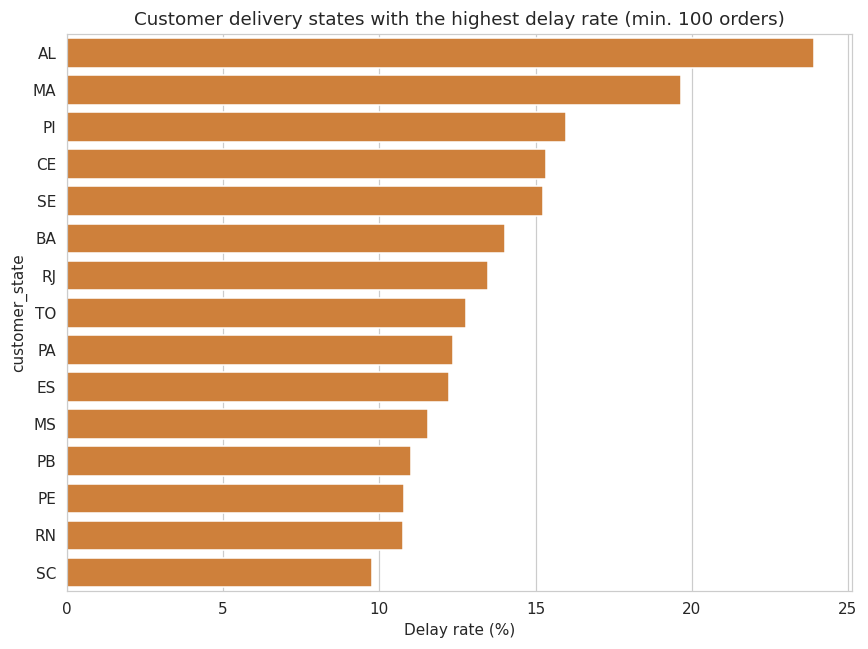

,delay_rate,n_orders
customer_state,,
AL,0.239295,397
MA,0.196653,717
PI,0.159664,476
CE,0.153245,1279
SE,0.152239,335
BA,0.140356,3256
RJ,0.134737,12350
TO,0.127737,274
PA,0.123679,946


In [4]:
state_delay = df.groupby("customer_state").agg(
    delay_rate=("is_delayed", "mean"), n_orders=("is_delayed", "count")
)
state_delay = state_delay[state_delay["n_orders"] >= 100].sort_values("delay_rate", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
top15 = state_delay.head(15)
sns.barplot(x=top15["delay_rate"] * 100, y=top15.index, ax=ax, color="#e67e22")
ax.set_xlabel("Delay rate (%)")
ax.set_title("Customer delivery states with the highest delay rate (min. 100 orders)")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/03_delay_by_state.png")
plt.show()

state_delay.head(10)

## 4. Product category effect

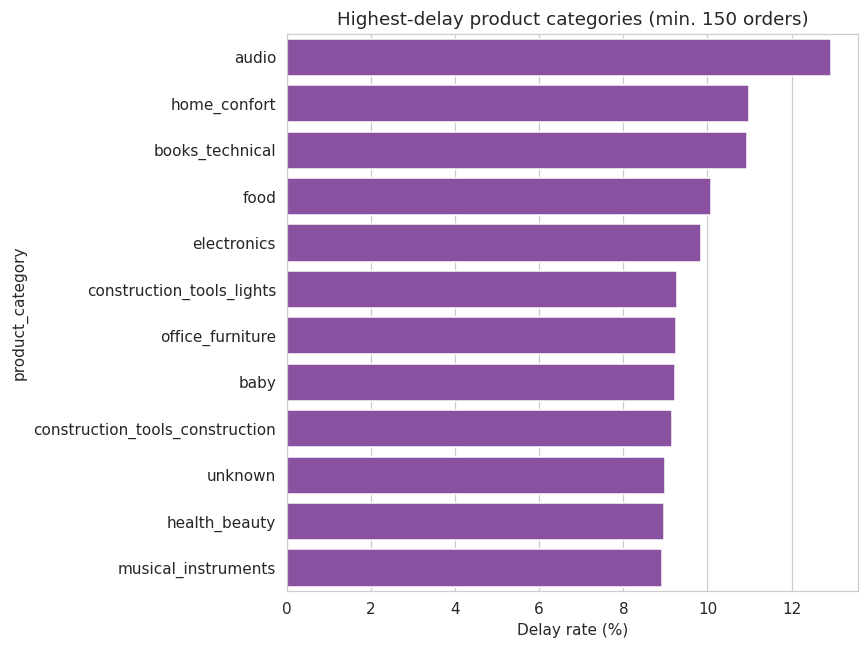

In [5]:
cat_delay = df.groupby("product_category").agg(
    delay_rate=("is_delayed", "mean"), n_orders=("is_delayed", "count")
)
cat_delay = cat_delay[cat_delay["n_orders"] >= 150].sort_values("delay_rate", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=cat_delay.head(12)["delay_rate"] * 100, y=cat_delay.head(12).index, ax=ax, color="#8e44ad")
ax.set_xlabel("Delay rate (%)")
ax.set_title("Highest-delay product categories (min. 150 orders)")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/04_delay_by_category.png")
plt.show()

## 5. Freight cost and shipping distance vs. delay

/tmp/ipykernel_223/1530876831.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="is_delayed", y="total_freight", data=df[df["total_freight"] < df["total_freight"].quantile(0.95)],
/tmp/ipykernel_223/1530876831.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["On time", "Delayed"])


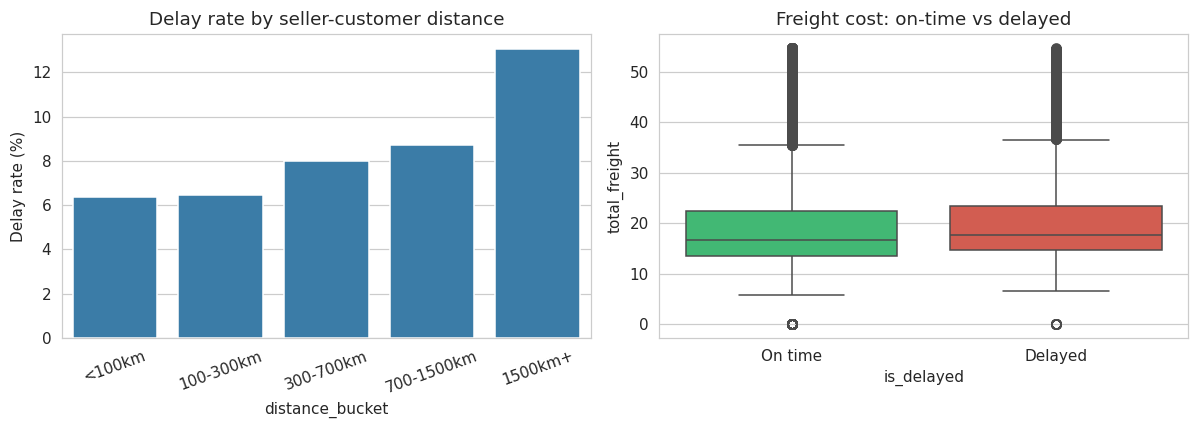

In [6]:
df["distance_bucket"] = pd.cut(
    df["seller_customer_distance_km"], bins=[0, 100, 300, 700, 1500, 5000],
    labels=["<100km", "100-300km", "300-700km", "700-1500km", "1500km+"]
)
dist_delay = df.groupby("distance_bucket", observed=True)["is_delayed"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=dist_delay.index, y=dist_delay.values * 100, ax=axes[0], color="#2980b9")
axes[0].set_ylabel("Delay rate (%)")
axes[0].set_title("Delay rate by seller-customer distance")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(x="is_delayed", y="total_freight", data=df[df["total_freight"] < df["total_freight"].quantile(0.95)],
            ax=axes[1], palette=["#2ecc71", "#e74c3c"])
axes[1].set_xticklabels(["On time", "Delayed"])
axes[1].set_title("Freight cost: on-time vs delayed")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/05_distance_freight_vs_delay.png")
plt.show()

Delay risk rises steadily with shipping distance, which is intuitive -
but the freight-cost picture is flatter than expected. Freight cost
alone is a weak signal; it's distance and the promised delivery window
that matter more (checked next).

## 6. Does a tighter promised delivery window predict delay?

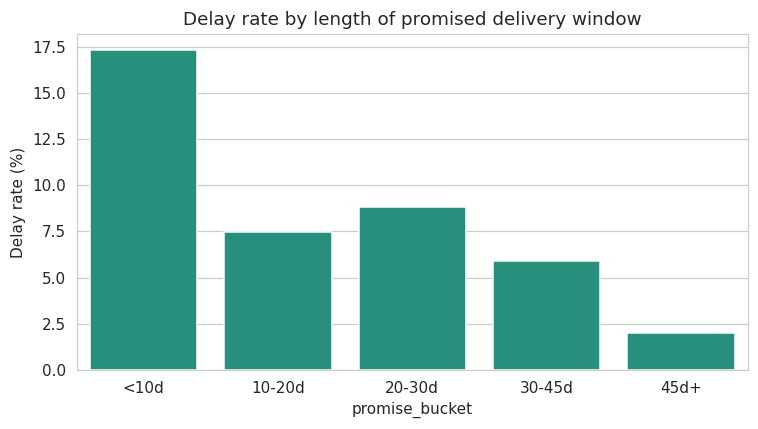

In [7]:
df["promised_days"] = (
    df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400
df["promise_bucket"] = pd.cut(
    df["promised_days"], bins=[0, 10, 20, 30, 45, 200],
    labels=["<10d", "10-20d", "20-30d", "30-45d", "45d+"]
)
promise_delay = df.groupby("promise_bucket", observed=True)["is_delayed"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=promise_delay.index, y=promise_delay.values * 100, ax=ax, color="#16a085")
ax.set_ylabel("Delay rate (%)")
ax.set_title("Delay rate by length of promised delivery window")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/06_promise_window_vs_delay.png")
plt.show()

Tight promises are the risky ones. Orders promised in under 10 days are late
17.3% of the time, more than twice the 8.1% average, while orders given 45+ days
are late only 2.0% of the time. The 20-30 day bucket is slightly worse than
10-20 days, so the effect is not perfectly smooth, but the overall direction is
clear: when the promised window is short there is little slack to absorb a slow
pickup or a long route. This is why the promised window is a model feature, and
why a flagged order driven by it gets the action "send the customer a realistic ETA".

## 7. Seller performance spread

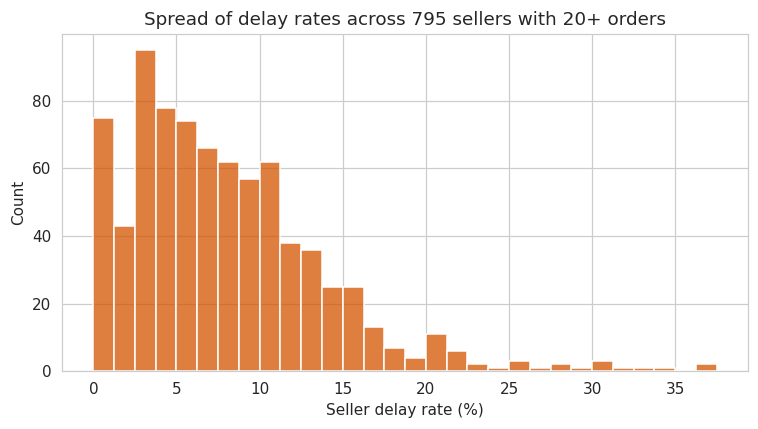

Sellers in the worst decile have a delay rate of 15.1% or higher, vs. a platform-wide average of 8.1%.


In [8]:
seller_perf = df.groupby("primary_seller_id").agg(
    delay_rate=("is_delayed", "mean"), n_orders=("is_delayed", "count")
)
seller_perf = seller_perf[seller_perf["n_orders"] >= 20]

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(seller_perf["delay_rate"] * 100, bins=30, ax=ax, color="#d35400")
ax.set_xlabel("Seller delay rate (%)")
ax.set_title(f"Spread of delay rates across {len(seller_perf):,} sellers with 20+ orders")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/07_seller_performance_spread.png")
plt.show()

print(f"Sellers in the worst decile have a delay rate of "
      f"{seller_perf['delay_rate'].quantile(0.9):.1%} or higher, vs. a "
      f"platform-wide average of {df['is_delayed'].mean():.1%}.")

Seller identity carries real signal - a subset of sellers are
chronically slower than the rest of the platform. This is exactly what
the leak-free `seller_historical_delay_rate` feature in notebook 04 is
built to capture.